# 01 — Exploratory Data Analysis
AI4I 2020 Predictive Maintenance Dataset. Exploration only — no production pipeline logic belongs here (see `src/`).

In [1]:
import math
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('../data/interim/raw_copy.csv')
df.head()

   UDI Product ID Type  Air temperature [K]  ...  HDF  PWF  OSF  RNF
0    1     M14860    M                298.1  ...    0    0    0    0
1    2     L47181    L                298.2  ...    0    0    0    0
2    3     L47182    L                298.1  ...    0    0    0    0
3    4     L47183    L                298.2  ...    0    0    0    0
4    5     L47184    L                298.2  ...    0    0    0    0

[5 rows x 14 columns]

## 1. Dataset overview

In [2]:
print('Shape:', df.shape)
print('\nDtypes:\n', df.dtypes)
print('\nMissing values:\n', df.isnull().sum())
print('\nDuplicate rows:', df.duplicated().sum())

Shape: (10000, 14)

Dtypes:
 UDI                          int64
Product ID                     str
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

Missing values:
 UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Duplicate rows: 0


**Findings:** 10,000 rows, 14 columns, 0 missing values, 0 duplicate rows, UDI is fully unique (identifier, not a feature).

## 2. Target distribution

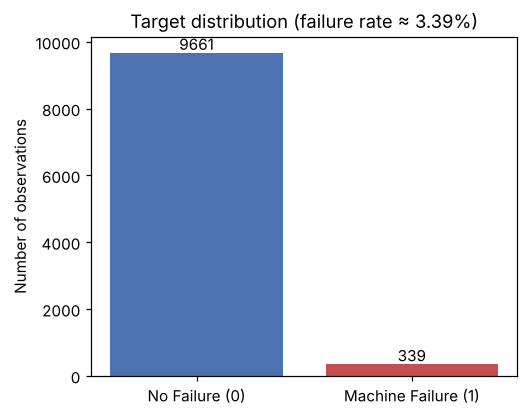

In [3]:
counts = df['Machine failure'].value_counts().sort_index()
failure_rate = df['Machine failure'].mean() * 100

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(['No Failure (0)', 'Machine Failure (1)'], counts.values, color=['#4C72B0', '#C44E52'])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width()/2, v + 100, str(v), ha='center')
ax.set_ylabel('Number of observations')
ax.set_title(f'Target distribution (failure rate \u2248 {failure_rate:.2f}%)')
plt.show()

**Figure 1.** Distribution of machine-failure and non-failure observations, showing the strong class imbalance in the dataset (failure rate ≈ 3.39%). This motivates using recall / F1 / PR-AUC rather than accuracy alone in later evaluation.

## 3. Sensor distributions

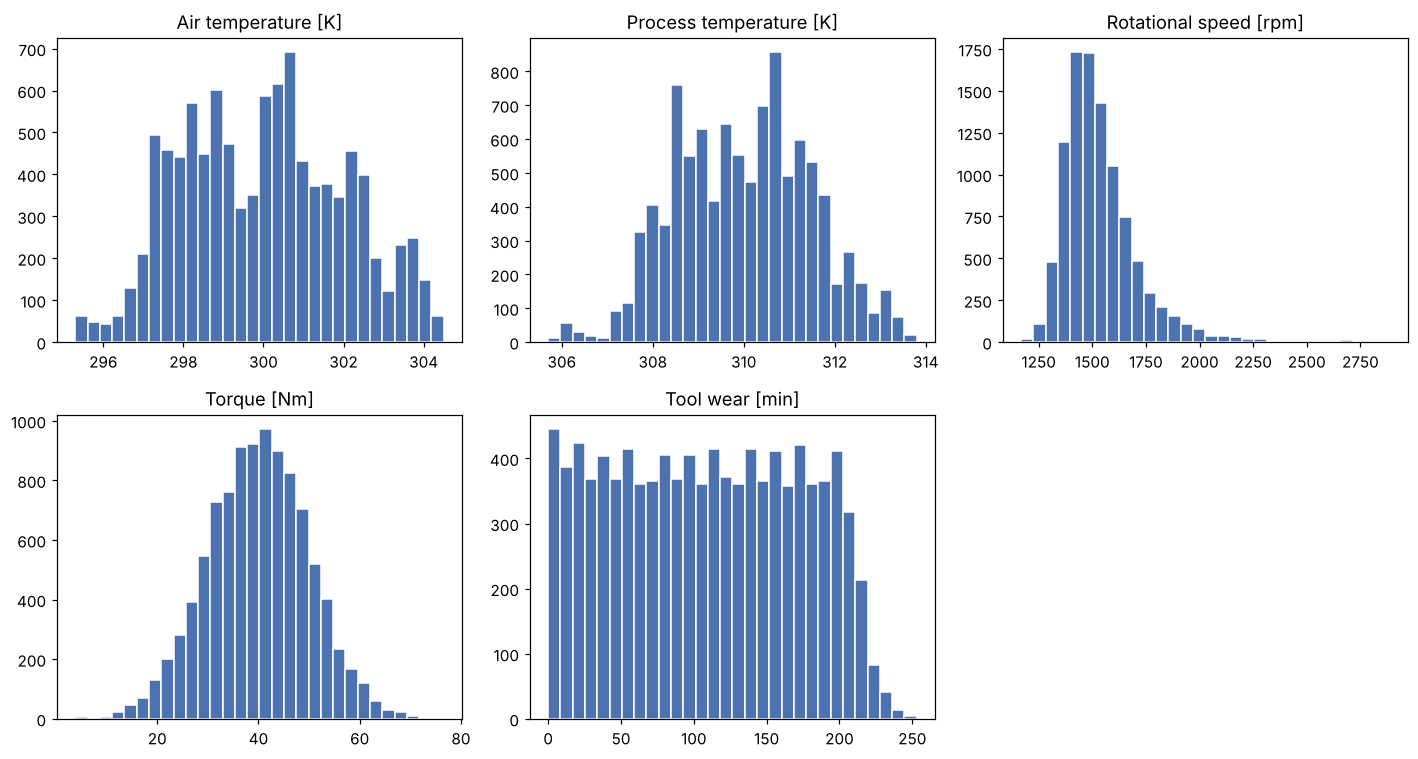

In [4]:
sensor_cols = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
axes = axes.flatten()
for ax, col in zip(axes, sensor_cols):
    ax.hist(df[col], bins=30, color='#4C72B0', edgecolor='white')
    ax.set_title(col)
axes[-1].axis('off')
plt.tight_layout()
plt.show()

## 4. Product quality distribution

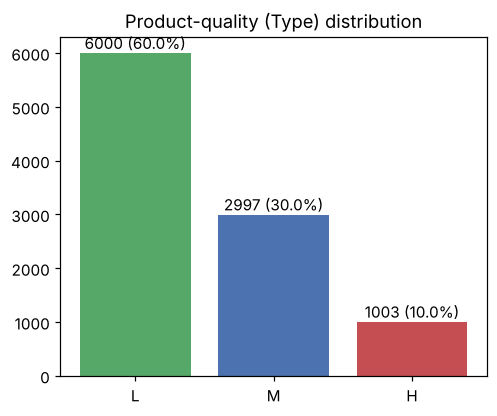

In [5]:
type_counts = df['Type'].value_counts().reindex(['L', 'M', 'H'])
fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(type_counts.index, type_counts.values, color=['#55A868', '#4C72B0', '#C44E52'])
for b, v in zip(bars, type_counts.values):
    ax.text(b.get_x() + b.get_width()/2, v + 80, f'{v} ({v/len(df)*100:.1f}%)', ha='center')
ax.set_title('Product-quality (Type) distribution')
plt.show()

**Figure 2.** Distribution of product-quality variants: L 60.0%, M 30.0%, H 10.0%.

## 5. Failure rate by product type

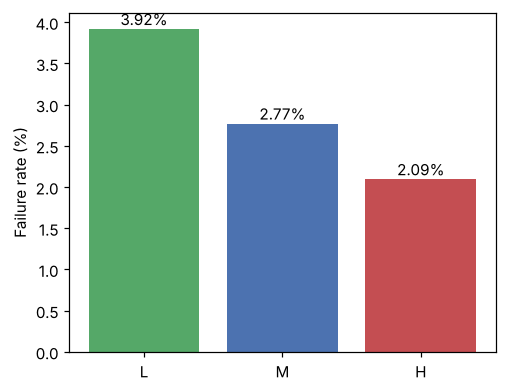

In [6]:
rate_by_type = (df.groupby('Type')['Machine failure'].mean() * 100).reindex(['L', 'M', 'H'])
fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(rate_by_type.index, rate_by_type.values, color=['#55A868', '#4C72B0', '#C44E52'])
for b, v in zip(bars, rate_by_type.values):
    ax.text(b.get_x() + b.get_width()/2, v + 0.05, f'{v:.2f}%', ha='center')
ax.set_ylabel('Failure rate (%)')
plt.show()

**Finding:** L-type machines fail more often (≈ 3.9%) than M (≈ 2.8%) or H (≈ 2.1%) — plausibly consistent with lower build quality tolerating less operational stress.

## 6. Sensor variables vs failure

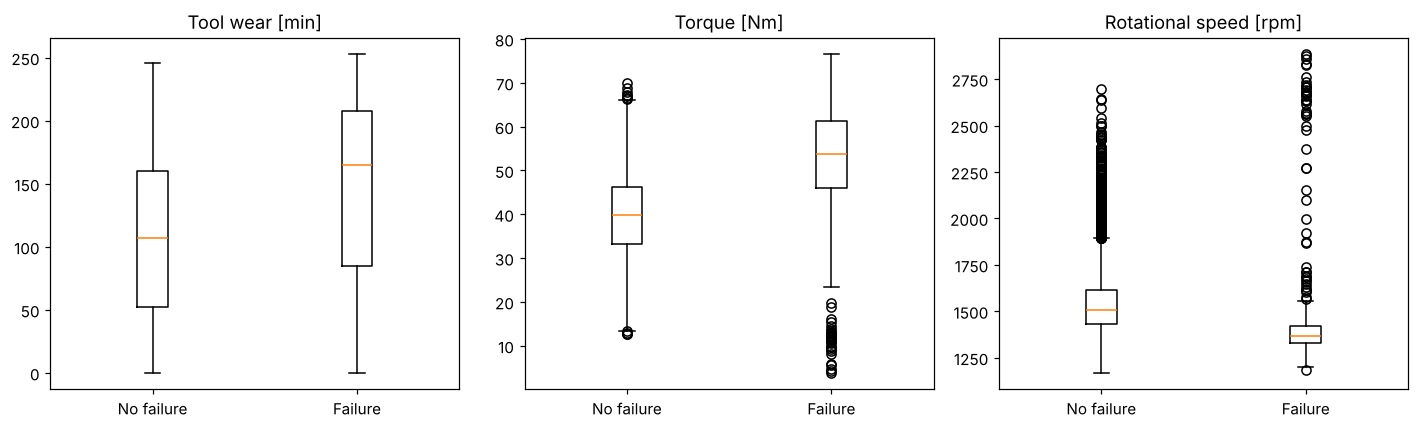

In [7]:
box_cols = ['Tool wear [min]', 'Torque [Nm]', 'Rotational speed [rpm]']
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, box_cols):
    data_by_class = [df.loc[df['Machine failure']==0, col], df.loc[df['Machine failure']==1, col]]
    ax.boxplot(data_by_class, tick_labels=['No failure', 'Failure'])
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 7. Engineering relationships

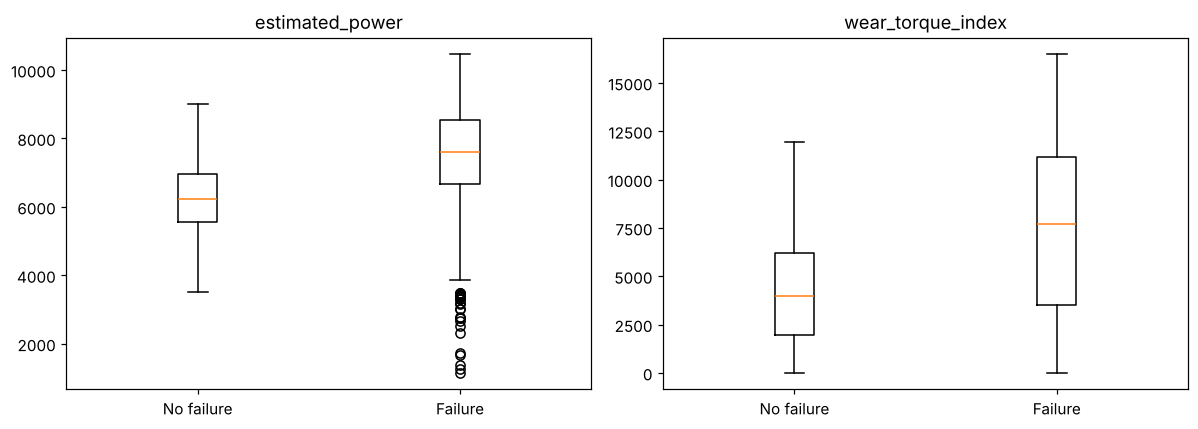

In [8]:
angular_speed = df['Rotational speed [rpm]'] * 2 * math.pi / 60
df['estimated_power'] = df['Torque [Nm]'] * angular_speed
df['wear_torque_index'] = df['Tool wear [min]'] * df['Torque [Nm]']

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, ['estimated_power', 'wear_torque_index']):
    data_by_class = [df.loc[df['Machine failure']==0, col], df.loc[df['Machine failure']==1, col]]
    ax.boxplot(data_by_class, tick_labels=['No failure', 'Failure'])
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Finding:** Failed observations skew toward higher `wear_torque_index` and (bimodally) higher `estimated_power`, with a distinct low-power outlier cluster among failures — consistent with multiple distinct failure mechanisms (e.g. OSF vs PWF) being lumped into a single binary target.

## 8. Failure modes (post-hoc analysis only, not model inputs)

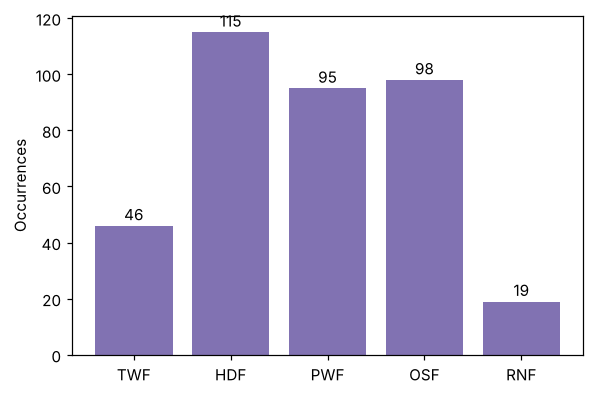

In [9]:
mode_cols = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']
mode_counts = df[mode_cols].sum()
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(mode_counts.index, mode_counts.values, color='#8172B2')
for b, v in zip(bars, mode_counts.values):
    ax.text(b.get_x() + b.get_width()/2, v + 2, str(v), ha='center')
ax.set_ylabel('Occurrences')
plt.show()

**Note:** 348 rows have at least one failure-mode flag set, but only 339 rows have `Machine failure == 1` (18 mode=1/failure=0 mismatches, 9 failure=1/no-mode mismatches). This is a known inherent inconsistency in the AI4I 2020 dataset — handled as a *warning*, not a hard failure, in the Data Quality Gate (Phase 5).